Dataset Loaded Successfully!
Input Shape: (569, 30)
Target Shape: (569, 1)
Training Samples: 426
Testing Samples: 143

DNN Training Started...

========== FIRST ITERATION ==========
Z1 = [ 0.32004607  0.35217869 -0.42725167 -0.53535977 -0.77589041  1.84062994
  0.01791423  0.88622607 -0.19478811 -0.37145095 -1.88836121 -1.31718432
 -0.50922787  2.53258453 -0.10353268  0.27304944]
A1 = [0.57933548 0.58714581 0.3947828  0.36926768 0.31520627 0.86302319
 0.50447844 0.70811075 0.45145636 0.40819047 0.13143144 0.21128713
 0.37537455 0.92639478 0.47413993 0.56784138]
Z2 = [ 0.35420376 -0.01082808 -0.84207927  0.03938456 -0.06564    -0.2334812
  1.21272541  0.26312125]
A2 = [0.58763661 0.49729301 0.30109705 0.50984487 0.48359589 0.44189343
 0.77078082 0.56540341]
Z3 = [0.99874985]
Output = [0.73081271]
MSE Loss = 0.24033791142576347
Epoch: 200 MSE Loss: 0.027278029910186997
Epoch: 400 MSE Loss: 0.01723648550991464
Epoch: 600 MSE Loss: 0.014347909332310822
Epoch: 800 MSE Loss: 0.01280746978215

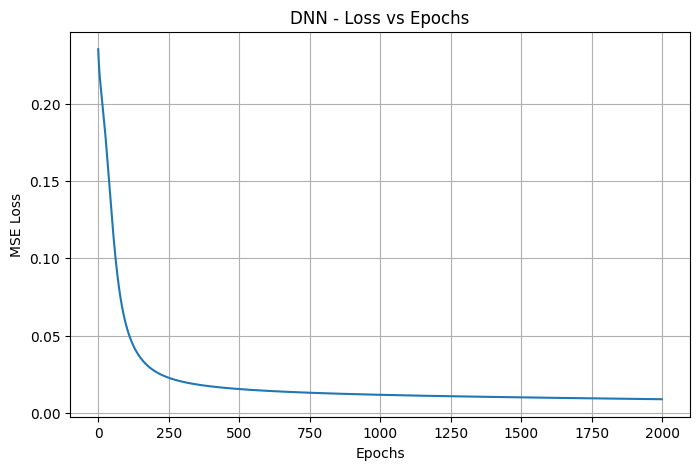

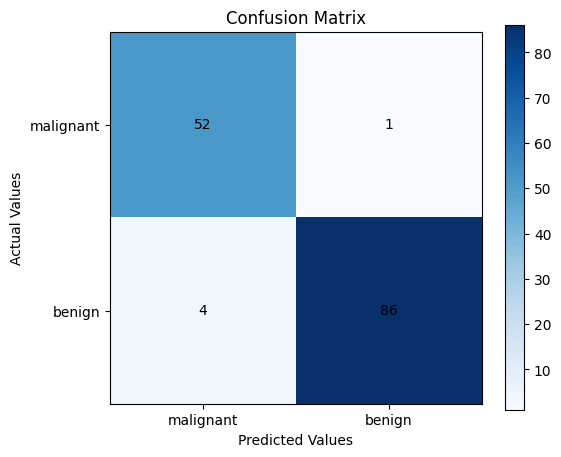


DNN Training Completed Successfully!


In [ ]:
# DLL Experiment 4
# Backpropagation Algorithm to Train DNN with 2 Hidden Layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


# 1. Load Dataset
data = load_breast_cancer()

X = data.data
Y = data.target.reshape(-1, 1)

print("Dataset Loaded Successfully!")
print("Input Shape:", X.shape)
print("Target Shape:", Y.shape)


# 2. Split Dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.25,
    random_state=42,
    stratify=Y
)

# 3. Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# 4. Define Network Architecture
input_neurons = X_train.shape[1]
hidden1_neurons = 16
hidden2_neurons = 8
output_neurons = 1

# Random weight initialization (Xavier)
rng = np.random.default_rng(42)

def initialize_weights(fan_in, fan_out):
    limit = np.sqrt(6 / (fan_in + fan_out))
    return rng.uniform(-limit, limit, (fan_in, fan_out))


W1 = initialize_weights(input_neurons, hidden1_neurons)
W2 = initialize_weights(hidden1_neurons, hidden2_neurons)
W3 = initialize_weights(hidden2_neurons, output_neurons)

# Initialize biases
b1 = np.zeros((1, hidden1_neurons))
b2 = np.zeros((1, hidden2_neurons))
b3 = np.zeros((1, output_neurons))


# 5. Activation Function
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))


# Sigmoid Derivative
def sigmoid_derivative(x):
    return x * (1 - x)


# 6. Loss Function
def mse_loss(y, output):
    return np.mean((y - output) ** 2)


# 7. Forward Propagation
def forward_propagation(X, W1, b1, W2, b2, W3, b3):

    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)

    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    z3 = np.dot(a2, W3) + b3
    output = sigmoid(z3)

    return z1, a1, z2, a2, z3, output


# 8. Training Parameters
learning_rate = 0.5
epochs = 2000

error_list = []

print("\nDNN Training Started...")


# 9. Backpropagation Training
for epoch in range(epochs):

    # Forward Propagation
    z1, a1, z2, a2, z3, output = forward_propagation(
        X_train, W1, b1, W2, b2, W3, b3
    )

    loss = mse_loss(Y_train, output)

    # Display First Iteration
    if epoch == 0:

        print("\n========== FIRST ITERATION ==========")

        print("Z1 =", z1[0])
        print("A1 =", a1[0])

        print("Z2 =", z2[0])
        print("A2 =", a2[0])

        print("Z3 =", z3[0])
        print("Output =", output[0])

        print("MSE Loss =", loss)


    # BACKPROPAGATION

    m = len(X_train)

    # Output Layer Error
    delta3 = (2 / m) * (output - Y_train) * sigmoid_derivative(output)

    dW3 = np.dot(a2.T, delta3)
    db3_grad = np.sum(delta3, axis=0, keepdims=True)


    # Hidden Layer 2 Error
    delta2 = np.dot(delta3, W3.T) * sigmoid_derivative(a2)

    dW2 = np.dot(a1.T, delta2)
    db2_grad = np.sum(delta2, axis=0, keepdims=True)


    # Hidden Layer 1 Error
    delta1 = np.dot(delta2, W2.T) * sigmoid_derivative(a1)

    dW1 = np.dot(X_train.T, delta1)
    db1_grad = np.sum(delta1, axis=0, keepdims=True)


    # UPDATE WEIGHTS AND BIASES

    W3 = W3 - learning_rate * dW3
    b3 = b3 - learning_rate * db3_grad

    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2_grad

    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1_grad


    # Store Loss
    _, _, _, _, _, updated_output = forward_propagation(
        X_train, W1, b1, W2, b2, W3, b3
    )

    loss = mse_loss(Y_train, updated_output)
    error_list.append(loss)


    # Display Loss
    if (epoch + 1) % 200 == 0:

        print("Epoch:", epoch + 1, "MSE Loss:", loss)


# 10. Final Training Output
z1, a1, z2, a2, z3, output = forward_propagation(
    X_train[:1], W1, b1, W2, b2, W3, b3
)

print("\n========== LAST ITERATION ==========")

print("Z1 =", z1)
print("A1 =", a1)

print("Z2 =", z2)
print("A2 =", a2)

print("Z3 =", z3)
print("Output =", output)


# 11. Testing and Prediction
_, _, _, _, _, test_output = forward_propagation(
    X_test, W1, b1, W2, b2, W3, b3
)

y_pred = (test_output >= 0.5).astype(int)


# 12. Model Performance
accuracy = accuracy_score(Y_test, y_pred)

final_loss = mse_loss(Y_test, test_output)

print("\n========== FINAL RESULT ==========")

print("Actual Values:", Y_test[:10].ravel())
print("Predicted Values:", y_pred[:10].ravel())

print("\nTest MSE Loss:", final_loss)
print("Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    Y_test,
    y_pred,
    target_names=data.target_names
))


# 13. Updated Weights and Biases
print("\n========== UPDATED WEIGHTS ==========")

print("W1 Shape:", W1.shape)
print("W2 Shape:", W2.shape)
print("W3 Shape:", W3.shape)

print("\nUpdated Biases:")
print("B1 =", b1)
print("B2 =", b2)
print("B3 =", b3)


# 14. Cost vs Epochs Graph
plt.figure(figsize=(8, 5))

plt.plot(error_list)

plt.title("DNN - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.grid(True)
plt.show()


# 15. Confusion Matrix
cm = confusion_matrix(Y_test, y_pred)

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0, 1], data.target_names)
plt.yticks([0, 1], data.target_names)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center")

plt.show()


print("\nDNN Training Completed Successfully!")